# 03F 深度学习接收机选题

参考 Sionna `tutorials/phy/Neural_Receiver.ipynb` 的思路：发射端仍使用传统 QPSK 调制和 AWGN 信道，接收端不用解析 LLR 公式，而是训练一个小型神经网络从接收符号估计 bit logits。任务是补全神经接收机、训练循环和 BER 评估。


## 实验任务与实现思路

本实验在传统 QPSK + AWGN 链路上，把接收端的解析 LLR 解映射替换为一个小型神经网络，
用监督学习的方式直接由接收复符号恢复发送比特：

1. **发射端不变**：随机比特经 Sionna QPSK 映射（$E_s=1$），叠加 AWGN，$N_0=1/(E_b/N_0\cdot 2)$；
2. **神经接收机**：输入特征 $[\mathrm{Re}(y),\ \mathrm{Im}(y),\ \log_{10}N_0]$，三层 MLP 输出每个符号两个比特的 logits；
3. **训练**：损失函数为逐比特二元交叉熵（BCEWithLogits），每步重新采样 $E_b/N_0\sim\mathcal{U}(0,10)$ dB，实现“混合信噪比训练”；
4. **评估**：与 Sionna APP Demapper（解析 LLR 硬判决）和 QPSK 理论曲线 $\frac12\mathrm{erfc}(\sqrt{\gamma_b})$ 对比，
   并补充固定信噪比训练 vs 混合训练的泛化性、学到的判决区域、以及推理复杂度三个补充实验。

训练数据使用独立的 `torch.Generator` 固定随机种子，两次运行得到的训练曲线与 BER 结果完全一致。

In [1]:
# 导入依赖，并准备 QPSK + AWGN 链路和 BER 工具函数。
from pathlib import Path
import sys
import time

# 从当前目录向上查找 src/sionna，优先使用本仓库源码。
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.special import erfc
from sionna.phy.mapping import Constellation, Mapper, Demapper
from sionna.phy.channel import AWGN
from sionna.phy import config as sionna_config

# 固定使用 CPU，保证没有 GPU 的学生电脑也能运行；只开 8 个线程，避免超线程争抢。
DEVICE = "cpu"
PRECISION = "single"
torch.set_num_threads(8)

# 图、数据输出目录：便于把过程性与结果性材料归档到同一文件夹。
FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

# 设置 Matplotlib 中文字体，避免图标题和坐标轴中文显示为问号。
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "Noto Sans CJK SC",
    "Arial Unicode MS",
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False

# Word 报告中的图宽约 14.4 cm，画布按英寸设置、插入时会被缩放，
# 因此把字号整体放大，使打印后的字号与正文（10.5 pt）接近（与 03A/01 一致）。
plt.rcParams.update(
    {
        "font.size": 13,
        "axes.labelsize": 13,
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)


def set_seed(seed=42):
    """固定 Python / NumPy / PyTorch / Sionna 四个随机源，使仿真结果可复现。"""
    torch.manual_seed(seed)
    np.random.seed(seed)
    sionna_config.seed = int(seed)


set_seed(42)

NUM_BITS_PER_SYMBOL = 2
BATCH_SIZE = 512               # 每步训练符号数 = 512 x 128
NUM_SYMBOLS = 128
TRAIN_EBN0_DB = 6.0            # 固定信噪比训练时的 Eb/N0（用于泛化性对比）
TRAIN_EBN0_MIN = 0.0           # 混合训练时 Eb/N0 均匀采样区间
TRAIN_EBN0_MAX = 10.0
TRAIN_STEPS = 2500             # 主模型训练步数
TRAIN_STEPS_FIXED = 2000       # 固定信噪比对照模型训练步数
EVAL_BATCH = 8192              # 每个 BER 评估点每次采样的符号数
EVAL_ROUNDS = 2                # 每个 BER 评估点重复采样轮数（共 2*8192*128 个符号）

# 训练数据专用的随机数发生器：与全局 RNG 解耦，保证两次运行训练数据逐位一致。
TRAIN_GENERATOR = torch.Generator(device="cpu").manual_seed(1234)


# 将 Eb/N0 转成 AWGN 模块需要的噪声功率谱密度 no：no = 1/(Eb/N0 * log2(M))。
def ebno_db_to_no(ebno_db, nbits, coderate=1.0):
    ebno = 10 ** (torch.as_tensor(ebno_db, dtype=torch.float32, device=DEVICE) / 10.0)
    return 1.0 / (ebno * nbits * coderate)


# 统计误比特数，BER 会在此基础上除以总 bit 数（与本项目 01/03A 口径一致）。
def count_bit_errors(b, b_hat):
    return int(torch.sum(b.to(torch.int32) != b_hat.to(torch.int32)).item())


def ber(b, b_hat):
    return count_bit_errors(b, b_hat) / b.numel()


def theory_qpsk_ber(ebno_db):
    """Gray 码 QPSK 在 AWGN 下的理论误比特率：Pb = 0.5*erfc(sqrt(Eb/N0))。"""
    gb = 10 ** (np.asarray(ebno_db, dtype=np.float64) / 10.0)
    return 0.5 * erfc(np.sqrt(gb))


const = Constellation("qam", NUM_BITS_PER_SYMBOL, precision=PRECISION, device=DEVICE)
mapper = Mapper(constellation=const, precision=PRECISION, device=DEVICE)
demapper = Demapper(
    "app", constellation=const, hard_out=False, precision=PRECISION, device=DEVICE
)
awgn = AWGN(precision=PRECISION, device=DEVICE)

print("QPSK 星座点:", np.round(const.points.cpu().numpy(), 4))
print("平均符号能量 Es =", float((const.points.abs() ** 2).mean()))

QPSK 星座点: [ 0.7071+0.7071j  0.7071-0.7071j -0.7071+0.7071j -0.7071-0.7071j]
平均符号能量 Es = 1.0


In [2]:
# 传统发射端：随机 bit -> Sionna QPSK Mapper -> Sionna AWGN 信道。
# 训练时传入显式 generator 生成比特与复高斯噪声，使训练集独立可复现；
# 评估时（generator=None）使用 Sionna AWGN 模块，噪声由全局种子控制。
def make_batch(batch_size, num_symbols, ebno_db, generator=None):
    shape = (batch_size, num_symbols * NUM_BITS_PER_SYMBOL)
    if generator is None:
        bits = torch.randint(0, 2, shape, dtype=torch.int32, device=DEVICE)
    else:
        bits = torch.randint(
            0, 2, shape, dtype=torch.int32, device=DEVICE, generator=generator
        )
    no = ebno_db_to_no(ebno_db, NUM_BITS_PER_SYMBOL)
    x = mapper(bits)
    if generator is None:
        y = awgn(x, no)
    else:
        # 复噪声：实部、虚部独立且各取方差 no/2，合成后复方差恰为 no。
        n = torch.randn(batch_size, num_symbols, 2, dtype=torch.float32, generator=generator)
        y = (x + torch.complex(n[..., 0], n[..., 1]) * torch.sqrt(no / 2.0)).to(torch.complex64)
    return bits, y, no


# Sionna Demapper 输出 LLR，本课程统一用 LLR > 0 判为 1。
def hard_bits(llr):
    return (llr > 0).to(torch.int32)


# 传统接收机基线：Sionna APP Demapper + 硬判决。
def baseline_receiver(y, no):
    return hard_bits(demapper(y, no))


bits, y, no = make_batch(4, 8, TRAIN_EBN0_DB)
print("bits shape:", bits.shape)
print("received symbols shape:", y.shape)
print("noise no:", float(no))

assert y.shape == (4, 8)

bits shape: torch.Size([4, 16])
received symbols shape: torch.Size([4, 8])
noise no: 0.12559431791305542


In [3]:
# 神经接收机：输入接收符号的实部、虚部和噪声功率，输出每个 QPSK 符号的两个 bit logits。
class NeuralReceiver(nn.Module):
    """三层 MLP 接收机：3 维特征 -> 64 -> 64 -> 2 个 logits。

    输入特征为 [Re(y), Im(y), log10(N0)]：前两项是接收复符号（同时携带幅度与相位信息），
    第三项让网络知道当前噪声水平，从而在混合信噪比训练时按噪声自适应地调整判决锐度。
    """

    def __init__(self, hidden_size=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, NUM_BITS_PER_SYMBOL),
        )

    def forward(self, y, no):
        no_t = torch.as_tensor(no, dtype=torch.float32, device=y.device)
        log10_no = torch.log10(no_t).expand_as(y.real)
        features = torch.stack([y.real, y.imag, log10_no], dim=-1)
        return self.net(features)


receiver = NeuralReceiver().to(DEVICE)

with torch.no_grad():
    logits = receiver(y, no)
print("logits shape:", logits.shape)
print("神经接收机参数量:", sum(p.numel() for p in receiver.parameters()))

assert logits.shape == (4, 8, NUM_BITS_PER_SYMBOL)

logits shape: torch.Size([4, 8, 2])
神经接收机参数量: 1250


图题：神经接收机训练损失随训练步的下降曲线（混合信噪比训练）


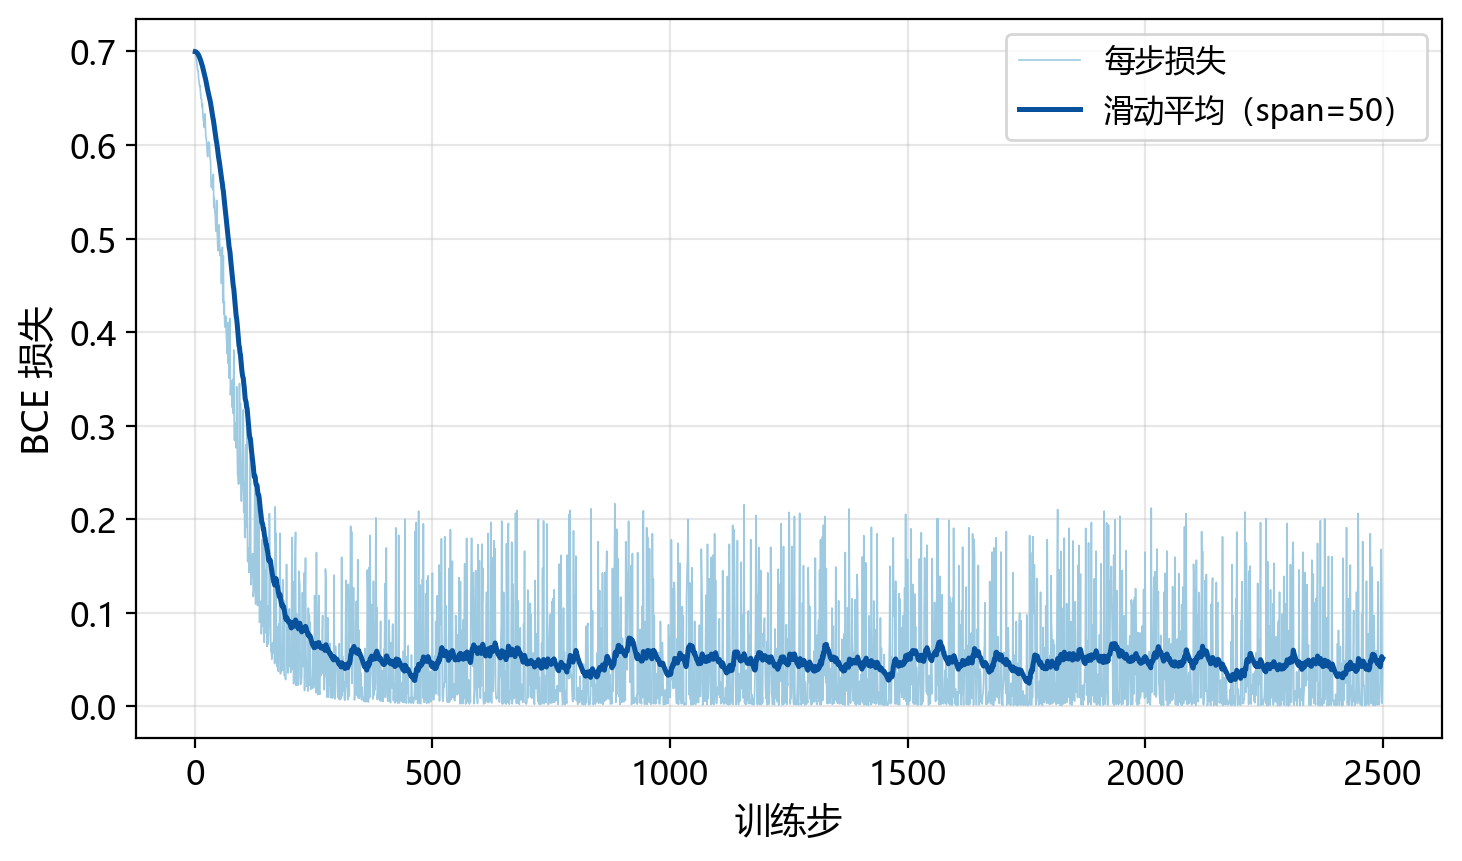

训练 2500 步耗时 69.3 s；首次损失 0.6997，最后 100 步平均损失 0.0461


In [4]:
# 训练目标参考 Sionna Neural Receiver 示例：接收机输出 logits，用 BCE 直接监督发送 bit。
def train_receiver(receiver, num_steps=TRAIN_STEPS, mixed_snr=True):
    """训练神经接收机。

    mixed_snr=True 时每步从 U(TRAIN_EBN0_MIN, TRAIN_EBN0_MAX) 采样一个 Eb/N0，
    让同一个网络覆盖整个工作信噪比区间；mixed_snr=False 时固定 TRAIN_EBN0_DB。
    训练数据全部由 TRAIN_GENERATOR 产生，因此训练过程完全可复现。
    """
    receiver.train()
    optimizer = torch.optim.Adam(receiver.parameters(), lr=1e-3)
    losses = []
    for step in range(num_steps):
        if mixed_snr:
            u = torch.rand(1, generator=TRAIN_GENERATOR).item()
            ebno_db = TRAIN_EBN0_MIN + u * (TRAIN_EBN0_MAX - TRAIN_EBN0_MIN)
        else:
            ebno_db = TRAIN_EBN0_DB
        bits, y, no = make_batch(BATCH_SIZE, NUM_SYMBOLS, ebno_db, generator=TRAIN_GENERATOR)
        target = bits.reshape(BATCH_SIZE, NUM_SYMBOLS, NUM_BITS_PER_SYMBOL).float()
        logits = receiver(y, no)
        loss = F.binary_cross_entropy_with_logits(logits, target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(float(loss.item()))
    return losses


t0 = time.perf_counter()
losses = train_receiver(receiver, num_steps=TRAIN_STEPS, mixed_snr=True)
train_time = time.perf_counter() - t0
loss_ema = pd.Series(losses).ewm(span=50, adjust=False).mean().to_numpy()

plt.figure(figsize=(7.5, 4.5))
plt.plot(np.arange(1, len(losses) + 1), losses, lw=0.6, color="#9ecae1", label="每步损失")
plt.plot(np.arange(1, len(losses) + 1), loss_ema, lw=1.8, color="#08519c", label="滑动平均（span=50）")
plt.xlabel("训练步")
plt.ylabel("BCE 损失")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03F_train_loss.png", dpi=200, bbox_inches="tight")
print("图题：神经接收机训练损失随训练步的下降曲线（混合信噪比训练）")
plt.show()

print(
    f"训练 {TRAIN_STEPS} 步耗时 {train_time:.1f} s；首次损失 {losses[0]:.4f}，"
    f"最后 100 步平均损失 {np.mean(losses[-100:]):.4f}"
)
pd.DataFrame(
    {"step": np.arange(1, len(losses) + 1), "loss": losses, "loss_ema": loss_ema}
).to_csv(DATA_DIR / "03F_train_loss.csv", index=False, encoding="utf-8-sig")

assert losses[-1] < losses[0]

Eb/N0(dB)  Sionna Demapper BER  Neural Receiver BER      理论 BER
     0.0          7.8726e-02           7.9059e-02    7.8650e-02
     2.0          3.7405e-02           3.7423e-02    3.7506e-02
     4.0          1.2517e-02           1.2628e-02    1.2501e-02
     6.0          2.3961e-03           2.3959e-03    2.3883e-03
     8.0          1.8811e-04           2.0099e-04    1.9091e-04
    10.0          2.8610e-06           5.4836e-06    3.8721e-06


图题：传统 LLR 接收机与神经接收机在 AWGN 下的 BER-Eb/N0 对比


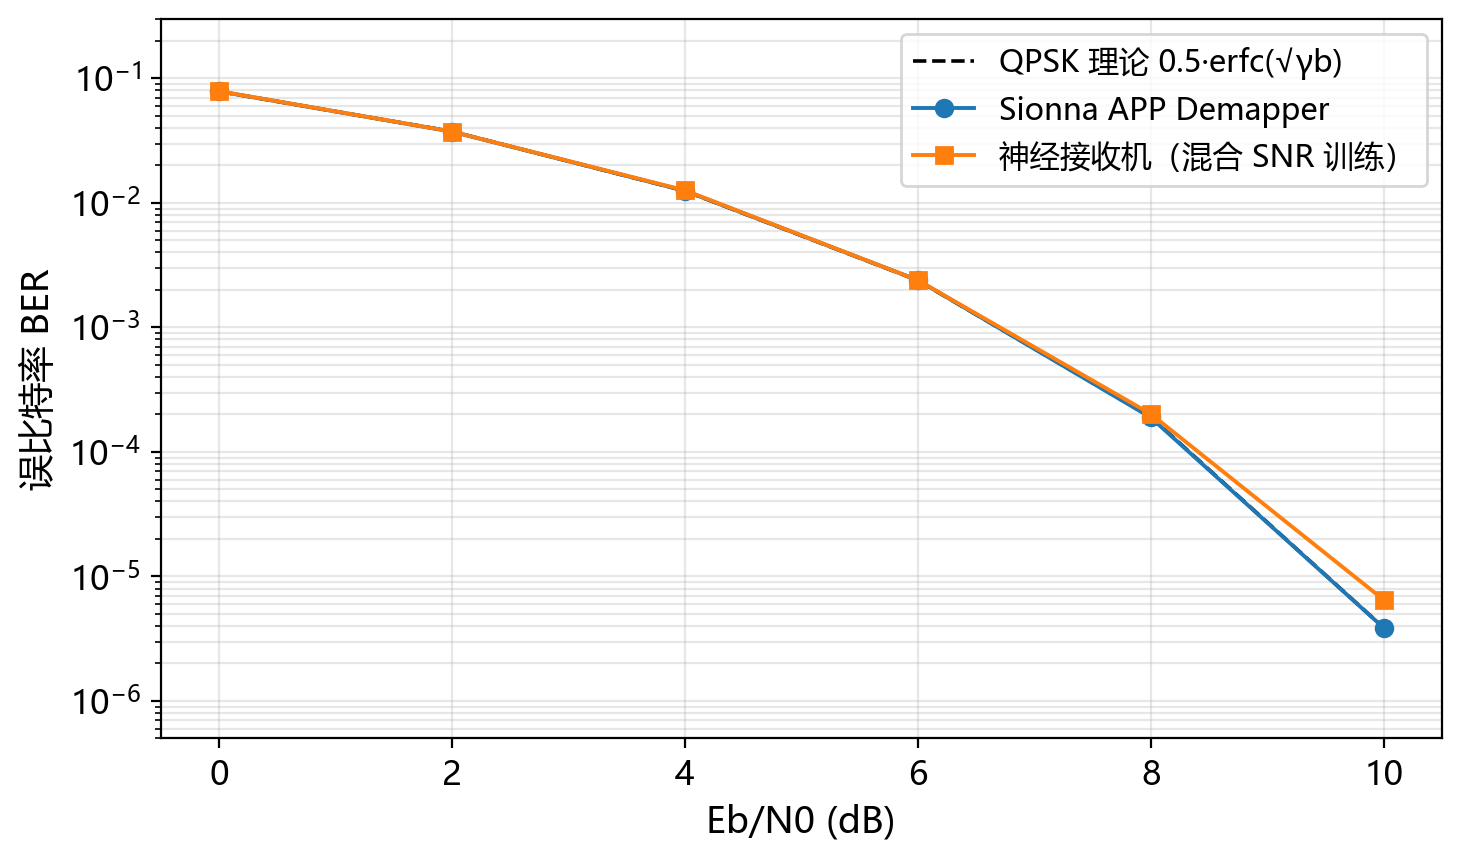

In [5]:
# 在多个 Eb/N0 点比较传统 Demapper 和神经接收机的 BER。
def neural_receiver_bits(receiver, y, no):
    receiver.eval()
    with torch.no_grad():
        logits = receiver(y, no)
    bits_hat = (logits > 0).to(torch.int32)
    return bits_hat.reshape(y.shape[0], -1)


def evaluate_receivers(
    receiver,
    ebno_db_list,
    batch_size=EVAL_BATCH,
    num_symbols=NUM_SYMBOLS,
    rounds=EVAL_ROUNDS,
):
    """逐 Eb/N0 统计误比特数，返回 (Eb/N0, Demapper BER, 神经接收机 BER, 理论 BER)。

    每个点重复 rounds 轮独立采样并累计误比特数（而不是对 BER 取平均），
    这样低 BER 点的统计抖动更小，曲线可以直接和理论公式对比。
    """
    rows = []
    for ebno_db in ebno_db_list:
        err_base = err_neural = total = 0
        for _ in range(rounds):
            bits, y, no = make_batch(batch_size, num_symbols, float(ebno_db))
            baseline_bits = baseline_receiver(y, no)
            neural_bits = neural_receiver_bits(receiver, y, no)
            err_base += count_bit_errors(bits, baseline_bits)
            err_neural += count_bit_errors(bits, neural_bits)
            total += bits.numel()
        rows.append(
            (
                float(ebno_db),
                err_base / total,
                err_neural / total,
                float(theory_qpsk_ber(float(ebno_db))),
            )
        )
    return rows


ebno_db = np.arange(0, 11, 2)

results = evaluate_receivers(receiver, ebno_db)
print("Eb/N0(dB)  Sionna Demapper BER  Neural Receiver BER      理论 BER")

for row in results:
    print(f"{row[0]:8.1f}  {row[1]:18.4e}  {row[2]:19.4e}  {row[3]:12.4e}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.semilogy([r[0] for r in results], [r[3] for r in results], "k--", lw=1.3, label="QPSK 理论 0.5·erfc(√γb)")
ax.semilogy([r[0] for r in results], [r[1] + 1e-6 for r in results], "o-", ms=6, lw=1.4, label="Sionna APP Demapper")
ax.semilogy([r[0] for r in results], [r[2] + 1e-6 for r in results], "s-", ms=6, lw=1.4, label="神经接收机（混合 SNR 训练）")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(5e-7, 3e-1)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03F_ber_compare.png", dpi=200, bbox_inches="tight")
print("图题：传统 LLR 接收机与神经接收机在 AWGN 下的 BER-Eb/N0 对比")
plt.show()

pd.DataFrame(
    {
        "ebno_db": [r[0] for r in results],
        "ber_demapper": [r[1] for r in results],
        "ber_neural": [r[2] for r in results],
        "ber_theory": [r[3] for r in results],
        "n_bits_per_point": EVAL_BATCH * NUM_SYMBOLS * NUM_BITS_PER_SYMBOL * EVAL_ROUNDS,
    }
).to_csv(DATA_DIR / "03F_ber.csv", index=False, encoding="utf-8-sig")

assert len(results) == len(ebno_db)

assert results[-1][2] < 0.20

## 补充实验一：固定信噪比训练 vs 混合信噪比训练（泛化能力）

模板中的网络默认只在单一 $E_b/N_0$ 处训练。若把 `log10(N0)` 作为输入，网络本应能随噪声水平自适应判决，
但**训练分布**决定了它在训练点附近的精度。下面用完全相同的网络结构、相同的训练数据种子和相近的训练步数，
对比“固定 $E_b/N_0=6$ dB 训练”与“$E_b/N_0\sim\mathcal{U}(0,10)$ dB 混合训练”在 0~10 dB 上的 BER，
并把实测 BER 反查到理论曲线上，换算成相对理论的等效信噪比代价（dB）。

固定 Eb/N0 = 6.0 dB 训练 2000 步耗时 47.4 s；最后 100 步平均损失 0.0068


Eb/N0(dB)  混合训练BER  固定训练BER  理论BER   混合代价(dB) 固定代价(dB)
     0.0   7.9059e-02   7.8910e-02  7.8650e-02         0.02         0.01
     2.0   3.7423e-02   3.7683e-02  3.7506e-02        -0.00         0.01
     4.0   1.2628e-02   1.2576e-02  1.2501e-02         0.02         0.01
     6.0   2.3959e-03   2.3599e-03  2.3883e-03         0.00        -0.01
     8.0   2.0099e-04   1.9193e-04  1.9091e-04         0.03         0.00
    10.0   5.4836e-06   5.0068e-06  3.8721e-06         0.15         0.11


图题：固定信噪比训练与混合信噪比训练的泛化能力对比


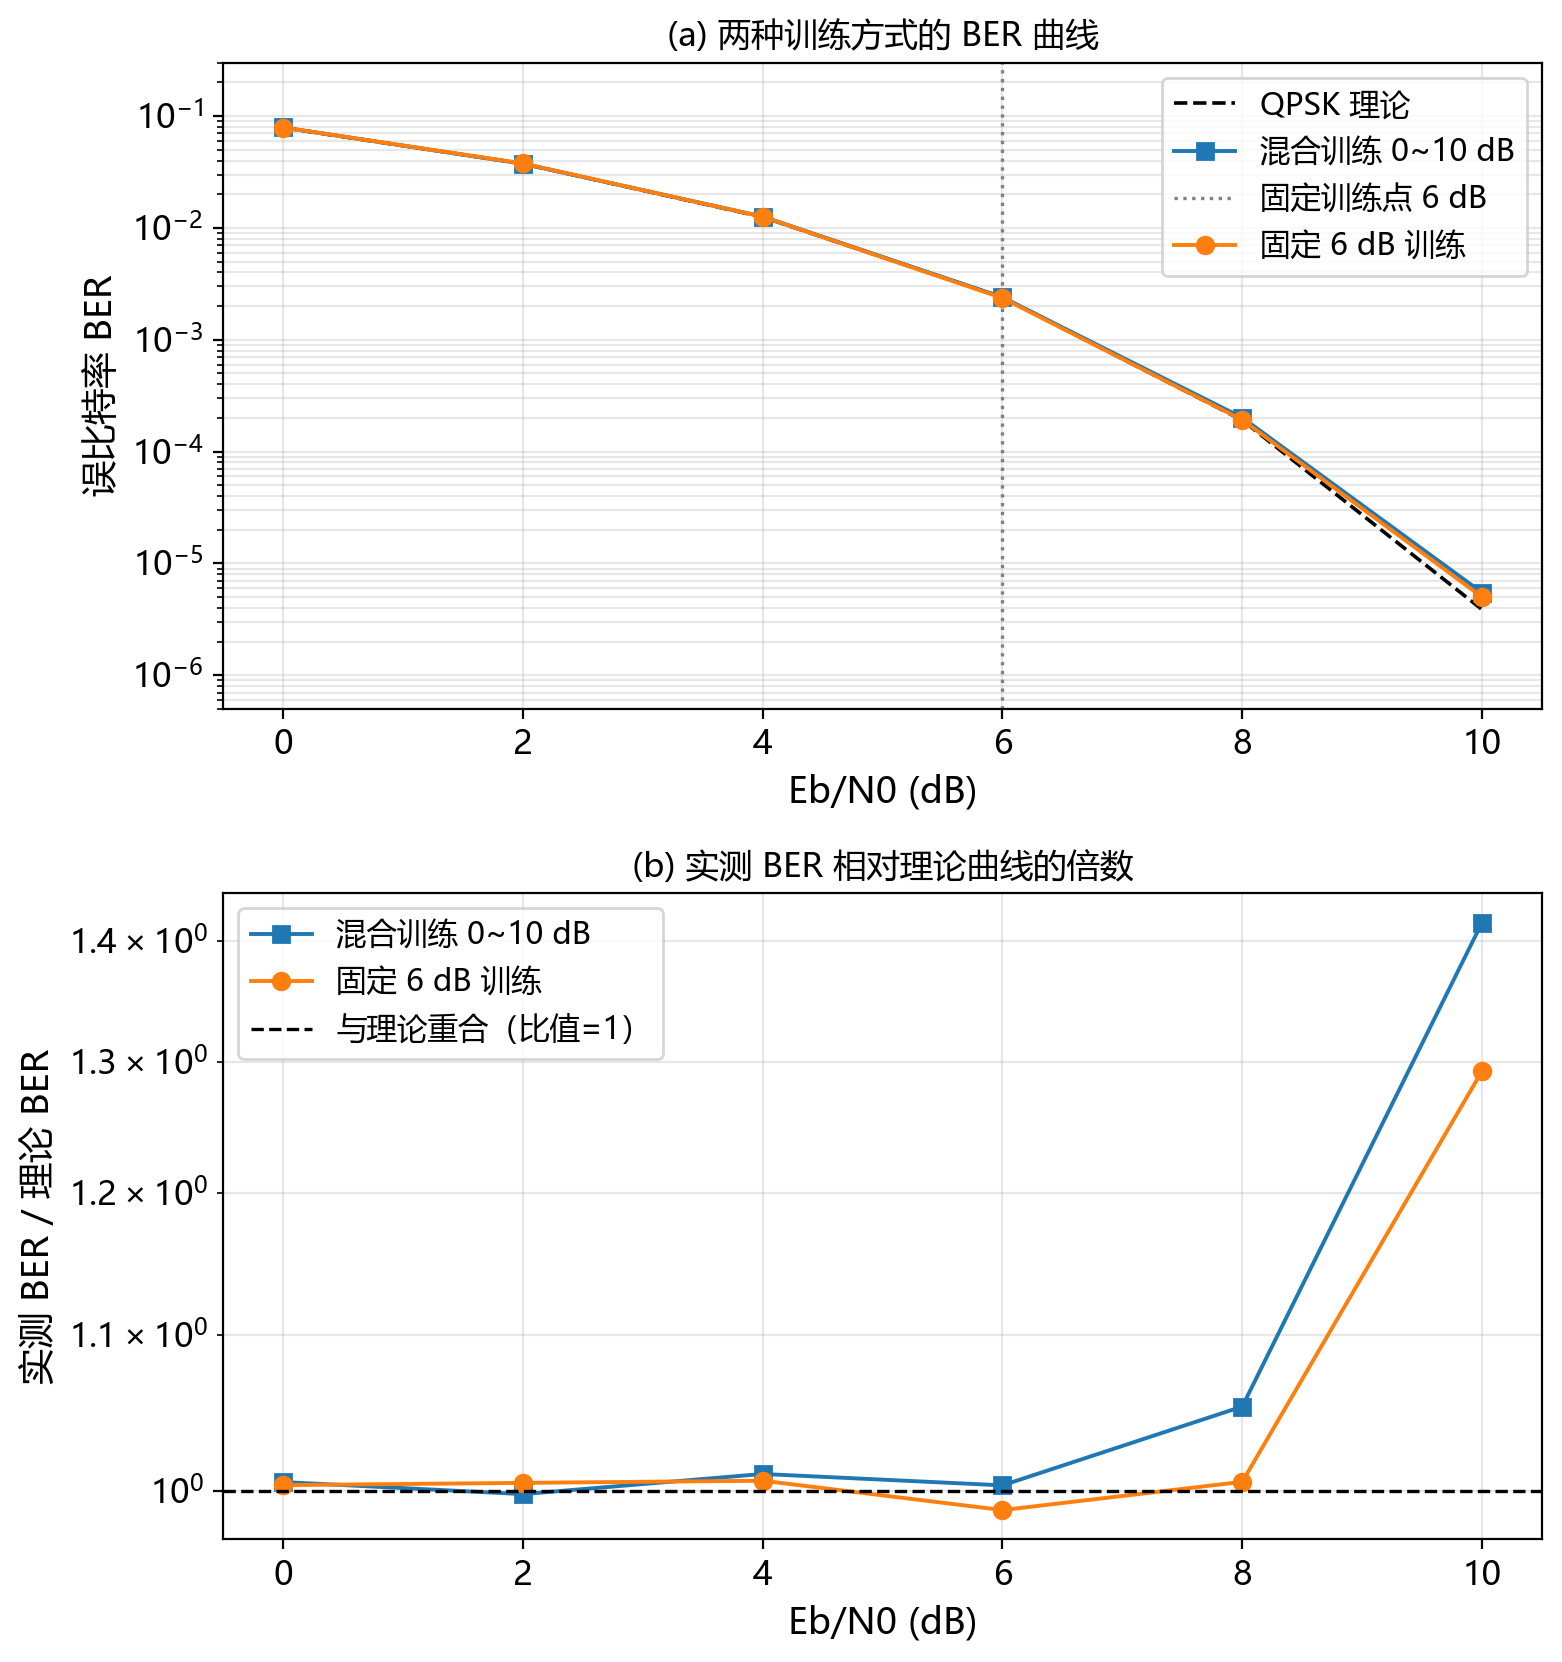

In [6]:
# 补充实验一：不改变网络结构，只改变训练时的信噪比分布，对比两者的泛化能力。
set_seed(2026)
TRAIN_GENERATOR = torch.Generator(device="cpu").manual_seed(1234)
receiver_fixed = NeuralReceiver().to(DEVICE)

t0 = time.perf_counter()
losses_fixed = train_receiver(receiver_fixed, num_steps=TRAIN_STEPS_FIXED, mixed_snr=False)
fixed_time = time.perf_counter() - t0
print(
    f"固定 Eb/N0 = {TRAIN_EBN0_DB} dB 训练 {TRAIN_STEPS_FIXED} 步耗时 {fixed_time:.1f} s；"
    f"最后 100 步平均损失 {np.mean(losses_fixed[-100:]):.4f}"
)

results_fixed = evaluate_receivers(receiver_fixed, ebno_db)


def equivalent_ebno_db(ber_value):
    """在 QPSK 理论 BER 曲线上反查达到该 BER 所需的 Eb/N0（二分法，单位 dB）。"""
    if ber_value <= 0 or not np.isfinite(ber_value):
        return float("nan")
    lo, hi = -5.0, 16.0
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if theory_qpsk_ber(mid) > ber_value:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)


print("Eb/N0(dB)  混合训练BER  固定训练BER  理论BER   混合代价(dB) 固定代价(dB)")
rows_general = []
for (db, _b, ber_mixed, ber_th), (_d, _, ber_fixed, _t) in zip(results, results_fixed):
    penalty_mixed = db - equivalent_ebno_db(ber_mixed)
    penalty_fixed = db - equivalent_ebno_db(ber_fixed)
    rows_general.append((db, ber_th, ber_mixed, ber_fixed, penalty_mixed, penalty_fixed))
    print(f"{db:8.1f}  {ber_mixed:11.4e}  {ber_fixed:11.4e}  {ber_th:9.4e}  {penalty_mixed:11.2f}  {penalty_fixed:11.2f}")

fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))

ax = axes[0]
ax.semilogy(ebno_db, [r[3] for r in results], "k--", lw=1.3, label="QPSK 理论")
ax.semilogy(ebno_db, [r[2] for r in results], "s-", ms=6, lw=1.4, label="混合训练 0~10 dB")
ax.axvline(TRAIN_EBN0_DB, color="gray", ls=":", lw=1.2, label="固定训练点 6 dB")
ax.semilogy(ebno_db, [r[2] for r in results_fixed], "o-", ms=6, lw=1.4, label="固定 6 dB 训练")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(5e-7, 3e-1)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
ax.set_title("(a) 两种训练方式的 BER 曲线", fontsize=12)

ax = axes[1]
ax.semilogy(ebno_db, [r[2] / r[3] for r in results], "s-", ms=6, lw=1.4, label="混合训练 0~10 dB")
ax.semilogy(ebno_db, [r[2] / r[3] for r in results_fixed], "o-", ms=6, lw=1.4, label="固定 6 dB 训练")
ax.axhline(1.0, color="k", ls="--", lw=1.2, label="与理论重合（比值=1）")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("实测 BER / 理论 BER")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
ax.set_title("(b) 实测 BER 相对理论曲线的倍数", fontsize=12)

plt.tight_layout()
plt.savefig(FIG_DIR / "03F_generalization.png", dpi=200, bbox_inches="tight")
print("图题：固定信噪比训练与混合信噪比训练的泛化能力对比")
plt.show()

pd.DataFrame(
    rows_general,
    columns=["ebno_db", "ber_theory", "ber_mixed_train", "ber_fixed_train", "penalty_mixed_db", "penalty_fixed_db"],
).to_csv(DATA_DIR / "03F_generalization.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(
    {"step": np.arange(1, len(losses_fixed) + 1), "loss": losses_fixed}
).to_csv(DATA_DIR / "03F_train_loss_fixed.csv", index=False, encoding="utf-8-sig")

## 补充实验二：神经接收机学到的判决区域

解析 LLR 接收机等价于在 $I$-$Q$ 平面上做两条过原点的直线判决（$I\gtrless 0$、$Q\gtrless 0$）。
神经接收机没有被告知任何星座先验，它学到的判决面是否也收敛到这套 MAP 边界？
下面把 $I$-$Q$ 平面网格化，输出网络对两个比特的 $P(b=1)$ 灰度面与 0.5 等值线，
并统计它与理想 MAP 判决在整个平面上的重合率。

Eb/N0(dB)    b0 判决重合率   b1 判决重合率
     0.0          99.28%          99.36%
     2.0          99.82%          99.83%
     4.0          99.75%          99.63%
     6.0          99.66%          99.58%
     8.0          99.36%          99.09%
    10.0          99.10%          98.72%


图题：神经接收机在 Eb/N0 = 6 dB 时学到的两比特判决区域


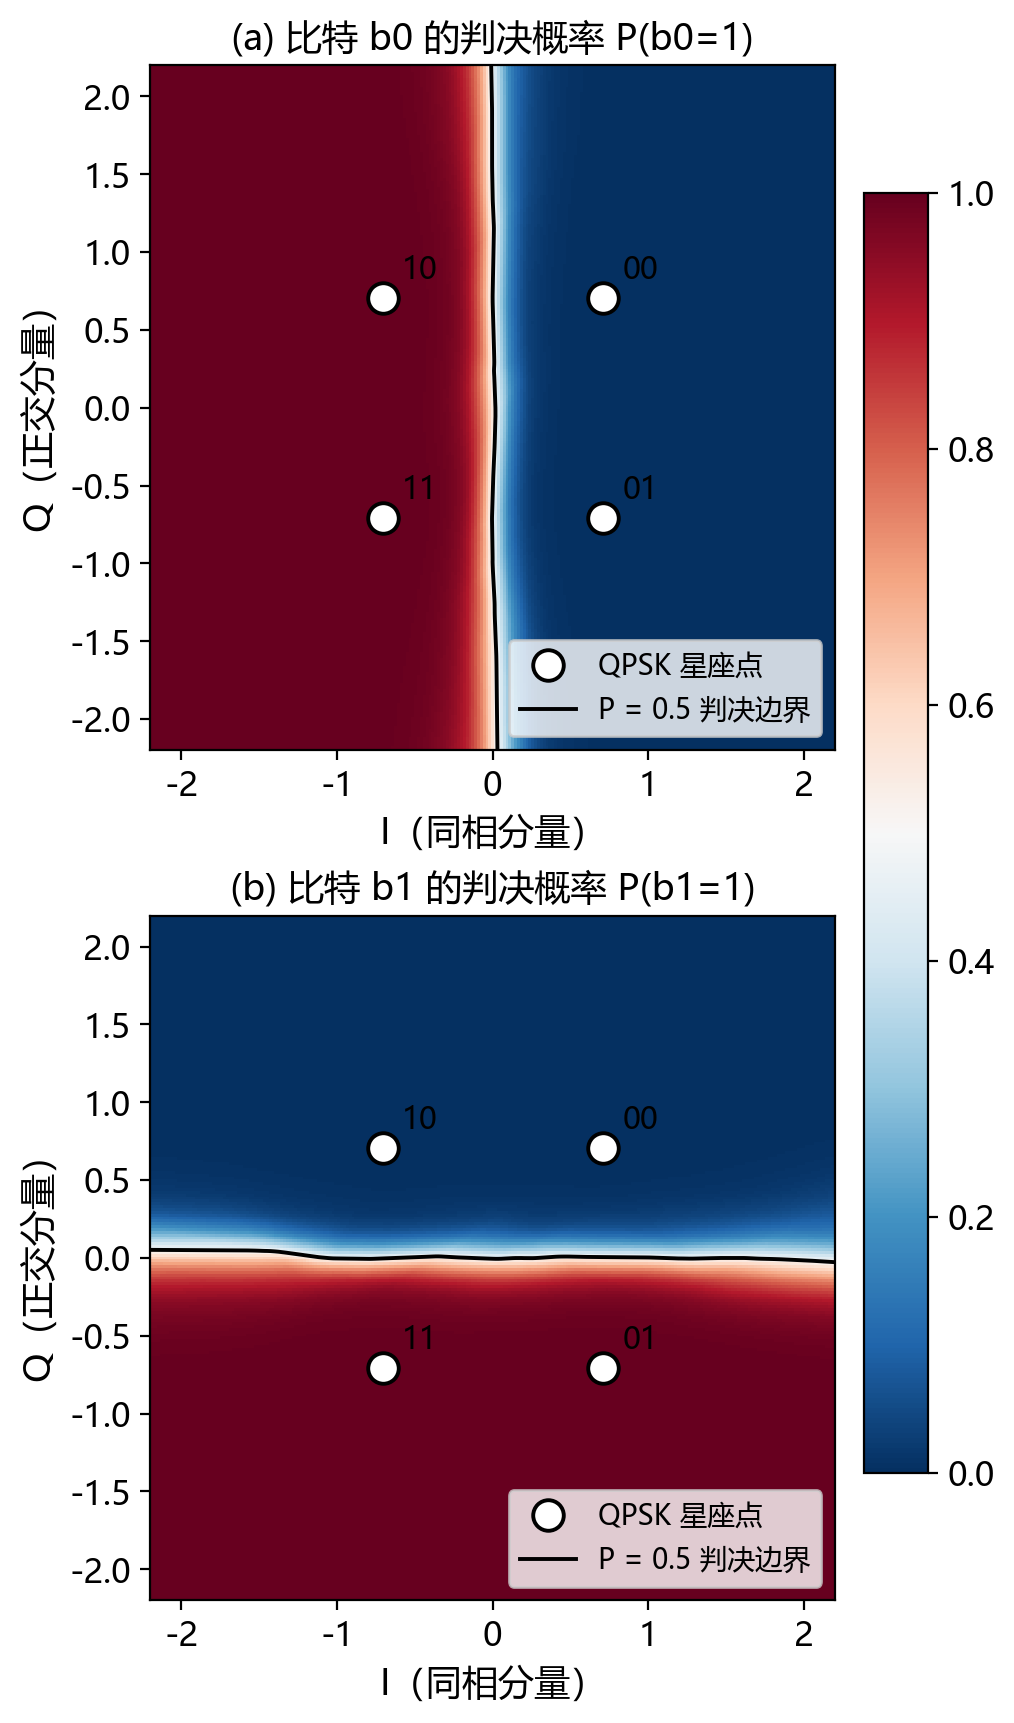

In [7]:
# 补充实验二：判决区域可视化 + 与理想 MAP 判决的一致率。
set_seed(2026)


def decision_probability(receiver, ebno_db, n=241, span=2.2):
    """在 I-Q 平面上输出两个比特 P(b=1) 的判决面。"""
    grid = torch.linspace(-span, span, n)
    gi, gq = torch.meshgrid(grid, grid, indexing="ij")
    y_grid = torch.complex(gi, gq).to(torch.complex64)
    no = ebno_db_to_no(ebno_db, NUM_BITS_PER_SYMBOL)
    receiver.eval()
    with torch.no_grad():
        p = torch.sigmoid(receiver(y_grid, no))
    return gi.numpy(), gq.numpy(), p.numpy()


def map_agreement(receiver, ebno_db, n=241):
    """返回网络判决与理想 MAP 判决（b0: I<0 判 1；b1: Q<0 判 1）在网格上的重合率。"""
    gi, gq, p = decision_probability(receiver, ebno_db, n=n)
    pred = p > 0.5
    ideal = np.stack([gi < 0, gq < 0], axis=-1)
    return float((pred[..., 0] == ideal[..., 0]).mean()), float((pred[..., 1] == ideal[..., 1]).mean())


rows_region = []
print("Eb/N0(dB)    b0 判决重合率   b1 判决重合率")
for db in [0.0, 2.0, 4.0, 6.0, 8.0, 10.0]:
    a0, a1 = map_agreement(receiver, db)
    rows_region.append((db, a0, a1))
    print(f"{db:8.1f}  {a0:14.2%}  {a1:14.2%}")

pd.DataFrame(rows_region, columns=["ebno_db", "agreement_b0", "agreement_b1"]).to_csv(
    DATA_DIR / "03F_decision_agreement.csv", index=False, encoding="utf-8-sig"
)

gi, gq, p = decision_probability(receiver, TRAIN_EBN0_DB)
fig, axes = plt.subplots(2, 1, figsize=(8, 8.5), layout="constrained")
for k, ax in enumerate(axes):
    mesh = ax.pcolormesh(gi, gq, p[..., k], cmap="RdBu_r", vmin=0.0, vmax=1.0)
    ax.contour(gi, gq, p[..., k], levels=[0.5], colors="k", linewidths=1.4)
    pts = const.points.cpu().numpy()
    ax.plot(pts.real, pts.imag, "ko", ms=11, mfc="w", mew=1.4, label="QPSK 星座点")
    for j, (xr, yi) in enumerate(zip(pts.real, pts.imag)):
        ax.annotate(f"{j:02b}", (xr, yi), xytext=(7, 7), textcoords="offset points", fontsize=11)
    ax.plot([], [], "k-", lw=1.4, label="P = 0.5 判决边界")
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.set_xlabel("I（同相分量）")
    ax.set_ylabel("Q（正交分量）")
    ax.set_aspect("equal")
    ax.set_title(f"({'ab'[k]}) 比特 b{k} 的判决概率 P(b{k}=1)", fontsize=13)
    ax.legend(loc="lower right", fontsize=10)
fig.colorbar(mesh, ax=axes, fraction=0.045, pad=0.02)
plt.savefig(FIG_DIR / "03F_decision_regions.png", dpi=200, bbox_inches="tight")
print("图题：神经接收机在 Eb/N0 = 6 dB 时学到的两比特判决区域")
plt.show()

## 补充实验三：推理复杂度对比

神经网络接收机用“查表式”的前向计算替代了 LLR 公式，代价是参数量与乘加运算。这里统计
网络的参数量，并在 100 万个符号上测量神经接收机与 Sionna APP Demapper 的 CPU 推理耗时，
为“用神经网络换掉解析模块”这一做法的计算开销给出量化参考。

In [8]:
# 补充实验三：推理复杂度与耗时（CPU，单线程计时的相对比较）。
set_seed(2026)
y_bench = torch.randn(1_000_000, dtype=torch.complex64) * 0.7
no_bench = ebno_db_to_no(6.0, NUM_BITS_PER_SYMBOL)


def bench(fn, repeat=3):
    fn()
    t0 = time.perf_counter()
    for _ in range(repeat):
        fn()
    return (time.perf_counter() - t0) / repeat


t_nn = bench(lambda: receiver(y_bench, no_bench))
t_llr = bench(lambda: demapper(y_bench, no_bench))
n_nn = sum(p.numel() for p in receiver.parameters())
n_sym = y_bench.numel()

n_mac = sum(m.in_features * m.out_features for m in receiver.net if isinstance(m, nn.Linear))
print(f"神经接收机参数量：{n_nn}（3-32-32-2 全连接）")
print(f"1e6 符号推理耗时：神经接收机 {t_nn:.3f} s（{t_nn / n_sym * 1e6:.3f} µs/符号），"
      f"Sionna APP Demapper {t_llr:.3f} s（{t_llr / n_sym * 1e6:.3f} µs/符号）")
print(f"神经网络前向的乘加次数约 {n_mac} 次/符号（不计激活函数）")

pd.DataFrame(
    [
        ("神经接收机", n_nn, t_nn, t_nn / n_sym * 1e6),
        ("Sionna APP Demapper", 0, t_llr, t_llr / n_sym * 1e6),
    ],
    columns=["接收机", "参数量", "1e6符号耗时_s", "每符号耗时_us"],
).to_csv(DATA_DIR / "03F_complexity.csv", index=False, encoding="utf-8-sig")

神经接收机参数量：1250（3-32-32-2 全连接）
1e6 符号推理耗时：神经接收机 0.072 s（0.072 µs/符号），Sionna APP Demapper 0.078 s（0.078 µs/符号）
神经网络前向的乘加次数约 1184 次/符号（不计激活函数）
